# 02: Preprocessing

Turns the 40,767 NC homes from notebook 01 into model-ready train / validation / test sets.
All logic lives in `src/preprocess.py`, so every model notebook gets identical data. This notebook runs it step by step and explains each choice.

| Step | What | Why (from notebook 01) |
|---|---|---|
| 1 | Remove impossible values and non-market sales | ~200 rows like $0 prices and 800,900 sqft hide real patterns; under-$40/sqft sales are not market prices |
| 2 | Split 70 / 15 / 15 | Train to learn, validation to tune settings (lambda, k), test touched once at the end |
| 3 | Fill missing lot size | 13% missing; dropping them would lose ~5,400 homes |
| 4 | ZIP location feature | Location matters (Fayetteville $122/sqft vs. Asheville $287) |
| 5 | Log transforms | Price skewness 7.75 → -0.11 after log |
| 6 | Standardize | Gradient descent, KNN and neural nets need features on similar scales |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

sys.path.insert(0, str(Path.cwd().parent / "src"))
import preprocess as pp
from load_data import load_nc_homes
from plot_style import apply_style, save, BLUE, ORANGE, TEXT_2, SEQ_BLUE

apply_style()
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## Step 1: Remove impossible values

Limits (inclusive): price $10k to $5M, house size 300 to 15,000 sqft, at most 10 beds, at most 10 baths, lot at most 100 acres.
A row can fail several rules, so the last column counts each removed row only once.

**Added after the first round of results:** price per sqft must be at least **$40**. In the first test evaluation, every one of the 10 worst predictions was priced at $9–$32/sqft (typical NC homes: about $185/sqft). These look like non-market sales (auctions, partial-ownership sales, typos), not normal home prices. $40/sqft is below the 1st percentile. Because the rule was added *after* looking at test results, the report states this openly, and notebook 04 compares results with and without it.

In [2]:
nc, load_steps = load_nc_homes()
clean, outlier_table = pp.remove_outliers(nc)
display(load_steps)
display(outlier_table)
print(f"Removed {len(nc) - len(clean):,} of {len(nc):,} rows ({(len(nc) - len(clean)) / len(nc):.2%}); {len(clean):,} remain")

,step,rows
0,All US listings,2226382
1,North Carolina only,85745
2,Status for_sale or sold (drop ready_to_build),84591
3,"Has price, bed, bath, house_size (drop land lots)",42946
4,Duplicates removed,40767


,rule,rows failing,removed (not already removed)
0,"price outside [10000, 5000000]",42,42
1,"house_size outside [300, 15000]",20,17
2,"bed outside [-, 10]",39,31
3,"bath outside [-, 10]",43,13
4,"acre_lot outside [-, 100]",45,40
5,price per sqft < $40 (non-market sales),241,234


Removed 377 of 40,767 rows (0.92%); 40,390 remain


## Step 2: Train / validation / test split

- **Train (70%)**: the models learn from these.
- **Validation (15%)**: used to pick settings such as Ridge's lambda or KNN's k, the same way as the regularization homework.
- **Test (15%)**: used **once**, at the very end, for the final numbers in the report. If we kept checking the test set while tuning, we'd be fitting to it and the final scores would look better than reality.

A fixed seed (42) makes the split identical every run. The splits should look alike, which the table checks:

In [3]:
trn, val, tst = pp.split(clean)
pd.DataFrame({
    name: {"rows": len(d), "median price": d.price.median(), "share sold": (d.status == "sold").mean(),
           "median sqft": d.house_size.median()}
    for name, d in [("train", trn), ("validation", val), ("test", tst)]
}).T

,rows,median price,share sold,median sqft
train,"28,273.000","334,900.000",0.400,"1,800.000"
validation,"6,058.000","332,000.000",0.410,"1,789.500"
test,"6,059.000","340,000.000",0.397,"1,827.000"


## Step 3: Missing lot size

13% of homes have no lot size. We fill each gap with the **median lot size of the training set**, not the whole dataset, so nothing from validation or test leaks in.
We also add a 0/1 column `acre_lot_missing`. If homes with a missing lot size differ in price (condos often have no lot listed, for example), the model can still learn that.

In [4]:
lot_median = trn.acre_lot.median()
print(f"Training median lot size: {lot_median:.2f} acres")
cmp = clean.assign(lot_missing=clean.acre_lot.isna()).groupby("lot_missing").agg(
    homes=("price", "size"), median_price=("price", "median"), median_sqft=("house_size", "median"))
cmp

Training median lot size: 0.35 acres


,homes,median_price,median_sqft
lot_missing,,,
False,35008,"339,900.000","1,840.000"
True,5382,"305,000.000","1,496.500"


## Step 4: ZIP location feature (target encoding)

The data has no coordinates, so location comes from the ZIP code. A ZIP code like 28207 is just a label: the number itself means nothing (28207 isn't "bigger" than 28205).
**Target encoding** replaces each ZIP with a number learned from the prices: the ZIP's median **price per sqft**, on a log scale.

**Smoothing small ZIPs.** 39% of ZIPs have fewer than 10 homes, and a median of 2 homes is mostly luck. So each ZIP's value is blended with its city's value:

value = (n × ZIP median + 10 × city value) / (n + 10)

A ZIP with 2 homes gets 2/12 ≈ 17% of its own median and 83% of the city's. A ZIP with 200 homes gets 200/210 ≈ 95% of its own. Cities are blended toward the state median the same way. ZIPs never seen in training fall back to their city, then the state.

Worked example from the training data:

In [5]:
enc = pp.fit_zip_encoding(trn)
lp = np.log(trn.price / trn.house_size)
rows = []
for z in ["28207", "28212", trn.zip_code.value_counts().index[-1]]:
    sub = trn[trn.zip_code == z]
    city = sub.city.mode().iloc[0]
    n = len(sub)
    rows.append({
        "zip": z, "city": city, "homes (n)": n,
        "ZIP median $/sqft": np.exp(lp[sub.index].median()),
        "city value $/sqft": np.exp(enc["city"][city]),
        "weight on ZIP": n / (n + pp.SMOOTHING_M),
        "final value $/sqft": np.exp(enc["zip"][z]),
    })
pd.DataFrame(rows).style.format({"ZIP median $/sqft": "${:,.0f}", "city value $/sqft": "${:,.0f}",
                                 "final value $/sqft": "${:,.0f}", "weight on ZIP": "{:.0%}"})

,zip,city,homes (n),ZIP median $/sqft,city value $/sqft,weight on ZIP,final value $/sqft
0,28207,Charlotte,91,$397,$212,90%,$373
1,28212,Charlotte,148,$186,$212,94%,$187
2,28642,Jonesville,1,$93,$171,9%,$162


### Why training rows use out-of-fold values

If a training home's own price goes into its ZIP's median, the feature already contains part of the answer. In a ZIP with one home, the feature *is* that home's price per sqft.
The model then learns to over-trust the feature, which looks great on training data and fails on new homes. This is **target leakage**.

The fix: split the training set into 5 folds. Each fold's ZIP values are computed from the **other 4** folds only, so no home ever sees its own price.
Validation and test homes use values from the full training set, which is fine because their prices were never used.

The experiment below compares both versions using a one-feature linear regression (`np.polyfit`): predict log price from the ZIP feature alone, and measure R² on training vs. validation data.

In [6]:
def r2(y, yhat):
    return 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)

y_trn, y_val = np.log(trn.price).values, np.log(val.price).values
val_feat = pp.apply_zip_encoding(val, enc).values
results = {}
for name, trn_feat in [("in-sample (leaky)", pp.apply_zip_encoding(trn, enc).values),
                       ("out-of-fold (ours)", pp.zip_encoding_out_of_fold(trn).values)]:
    b1, b0 = np.polyfit(trn_feat, y_trn, 1)
    results[name] = {"train R²": r2(y_trn, b0 + b1 * trn_feat),
                     "validation R²": r2(y_val, b0 + b1 * val_feat), "slope": b1}
pd.DataFrame(results).T

,train R²,validation R²,slope
in-sample (leaky),0.285,0.271,1.147
out-of-fold (ours),0.271,0.271,1.139


**Result:** the leaky version's training R² (0.285) is higher than its validation R² (0.271), so it looks better on data it has partly seen. The out-of-fold version's training R² (0.271) equals validation (0.271), so its training score is honest. Validation performance is the same for both here, because smoothing (weight n/(n+10)) already limits how much one home can affect its own ZIP value.

So for a simple linear model the leak is small. Out-of-fold encoding still matters, because flexible models (KNN, neural network) can latch onto a leaked signal much harder than a straight line can. It also keeps training scores comparable to validation scores, which the overfitting analysis relies on.

## Steps 5 and 6: Log transforms, final features, standardization

In [7]:
data = pp.build(save=True)
print("Saved:", [f"{n}.csv ({len(data[n]):,} rows)" for n in ["train", "val", "test"]])
print("\nModel inputs:", pp.FEATURES, "\nTarget:", pp.TARGET)
data["train"][pp.FEATURES + [pp.TARGET]].describe()

Saved: ['train.csv (28,273 rows)', 'val.csv (6,058 rows)', 'test.csv (6,059 rows)']

Model inputs: ['log_house_size', 'bed', 'bath', 'log_acre_lot', 'acre_lot_missing', 'sold', 'zip_log_ppsf'] 
Target: log_price


,log_house_size,bed,bath,log_acre_lot,acre_lot_missing,sold,zip_log_ppsf,log_price
count,"28,273.000","28,273.000","28,273.000","28,273.000","28,273.000","28,273.000","28,273.000","28,273.000"
mean,7.508,3.221,2.646,0.433,0.133,0.400,5.225,12.735
std,0.440,0.910,1.072,0.482,0.340,0.490,0.289,0.633
min,5.724,1.000,1.000,0.000,0.000,0.000,4.378,10.043
25%,7.208,3.000,2.000,0.199,0.000,0.000,5.026,12.346
50%,7.496,3.000,3.000,0.300,0.000,0.000,5.212,12.722
75%,7.794,4.000,3.000,0.457,0.000,1.000,5.400,13.071
max,9.433,10.000,10.000,4.589,1.000,1.000,6.808,15.425


| Feature | Meaning |
|---|---|
| `log_house_size` | log(sqft). On a log-log scale, a coefficient reads as "1% bigger home → b% higher price" |
| `bed`, `bath` | counts, kept as-is |
| `log_acre_lot` | log(1 + acres); the +1 handles 0-acre lots |
| `acre_lot_missing` | 1 if the lot size was filled in |
| `sold` | 1 = sold (sale price), 0 = for sale (asking price) |
| `zip_log_ppsf` | smoothed ZIP median log($/sqft) |

**Dropped:** `brokered_by` and `street` (anonymized ID numbers), `prev_sold_date` (for sold homes it's the sale date, which would reveal the status), `state` (always NC), and `city` and `zip_code` themselves (their information is inside `zip_log_ppsf`).

**Standardization:** each feature becomes (value − training mean) / training std, so every feature is centered at 0 with spread 1.
Without it, gradient descent takes tiny steps along features with small ranges and huge steps along large ones, and KNN's distances are dominated by whichever feature has the biggest numbers.
This is the `Standardize` class from the GD & LMS homework, fit on training data only.

In [8]:
X_trn, y_trn, X_val, y_val, X_tst, y_tst, scaler = pp.get_arrays(data)
print("Shapes:", X_trn.shape, X_val.shape, X_tst.shape)
print("Training means after standardizing:", X_trn.mean(axis=0).round(3))
print("Training stds after standardizing: ", X_trn.std(axis=0).round(3))
pd.DataFrame({"training mean": scaler.mean, "training std": scaler.std}, index=pp.FEATURES)

Shapes: (28273, 7) (6058, 7) (6059, 7)
Training means after standardizing: [-0. -0.  0. -0. -0.  0. -0.]
Training stds after standardizing:  [1. 1. 1. 1. 1. 1. 1.]


,training mean,training std
log_house_size,7.508,0.440
bed,3.221,0.910
bath,2.646,1.072
log_acre_lot,0.433,0.482
acre_lot_missing,0.133,0.340
sold,0.400,0.490
zip_log_ppsf,5.225,0.289


,correlation with log price
sold,-0.145
acre_lot_missing,-0.071
log_acre_lot,0.179
bed,0.469
zip_log_ppsf,0.521
bath,0.664
log_house_size,0.703


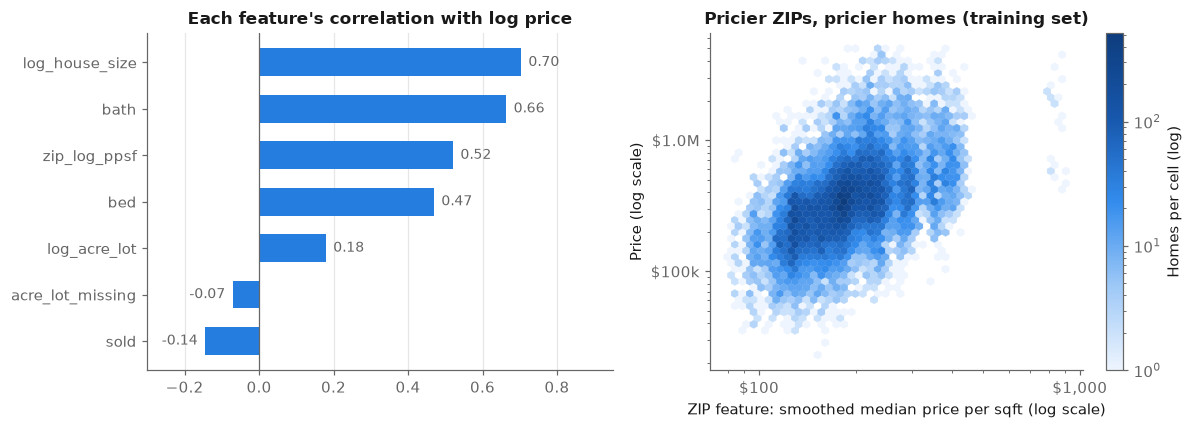

In [9]:
corr = data["train"][pp.FEATURES + [pp.TARGET]].corr()[pp.TARGET].drop(pp.TARGET).sort_values()
display(corr.to_frame("correlation with log price"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].barh(corr.index, corr.values, color=BLUE, height=0.6)
axes[0].axvline(0, color=TEXT_2, linewidth=0.8)
for y, v in enumerate(corr.values):
    axes[0].text(v + (0.02 if v >= 0 else -0.02), y, f"{v:.2f}", va="center",
                 ha="left" if v >= 0 else "right", fontsize=9, color=TEXT_2)
axes[0].set_xlim(-0.3, 0.95)
axes[0].set_title("Each feature's correlation with log price")
axes[0].grid(axis="y", visible=False)

t = data["train"]
hb = axes[1].hexbin(np.exp(t.zip_log_ppsf), t.price, gridsize=45, xscale="log", yscale="log",
                    cmap=SEQ_BLUE, mincnt=1, bins="log", linewidths=0.2)
axes[1].set_xlabel("ZIP feature: smoothed median price per sqft (log scale)")
axes[1].set_ylabel("Price (log scale)")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x:,.0f}"))
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M" if x >= 1e6 else f"${x/1e3:.0f}k"))
axes[1].set_title("Pricier ZIPs, pricier homes (training set)")
axes[1].grid(False)
fig.colorbar(hb, ax=axes[1]).set_label("Homes per cell (log)")
fig.tight_layout()
save(fig, "fig10_features_vs_target")
plt.show()

## Summary

1. **Cleaning:** removed 377 of 40,767 rows (0.92%) → **40,390 homes**. 143 were impossible values; **234 were non-market sales under $40/sqft** (a rule added after the first round of results, see notebook 04).
2. **Split** (seed 42): **28,273 train / 6,058 validation / 6,059 test**. Similar medians ($332k–$340k) and share sold (40–41%).
3. **Lot size:** 5,382 missing values filled with the training median (0.35 acres), plus an `acre_lot_missing` flag. Homes without a lot size are cheaper ($305k vs. $340k) and smaller (1,497 vs. 1,840 sqft).
4. **ZIP feature** examples: 28207 Charlotte (91 homes, 90% own weight) $397 → **$373**; 28212 Charlotte (148 homes) $186 → **$187**; 28642 Jonesville (1 home, 9% own weight) $93 → **$162**, pulled toward the city's $171.
5. **Leakage check:** the out-of-fold training R² (0.271) equals validation (0.271); the leaky version inflates training R² (0.285).
6. **Final inputs (7):** log_house_size, bed, bath, log_acre_lot, acre_lot_missing, sold, zip_log_ppsf. **Target:** log(price).
7. **Correlation with log price:** size 0.70, bath 0.66, ZIP 0.52, bed 0.47, lot 0.18, lot missing −0.07, sold −0.15.
8. **Standardized** with training mean and std (mean 0, std 1 on training data).